# 01 · Risk model: properties, sensitivity and an uncertainty-aware alternative
**Supports:** RQ3, concept note §7, experiment **E3** (design input).
**Data:** workbook DEMO rows + a *synthetic* 20-scenario register (seeded). Nothing here is an observation of a real product.

Questions this notebook answers before any SME data is collected:
1. What are the arithmetic properties of the v1.0 score `L × I × E` (ties, band coverage)?
2. How stable is the ranking under realistic assessor noise, and do other aggregations do better?
3. How sensitive is the residual score to the (often unverified) effectiveness assumption?
4. Does an uncertainty-aware Monte Carlo (FAIR-inspired) ranking agree with the ordinal ranking?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from crasme import plotting; plotting.use()
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)
from crasme import risk as r

## 1 · Parity with the workbook
The Python model reproduces the Excel formulas exactly (also enforced by `tests/test_workbook.py` via LibreOffice recalculation).

In [2]:
demo = [r.RiskRow('DEMO-R01','DEMO-001','Unauthenticated management endpoint',4,5,4,0.5,0.2,150000),
        r.RiskRow('DEMO-R02','DEMO-001','Outdated dependency exploited',3,4,4,0.4,0.1,80000)]
pd.DataFrame([{ 'risk': d.risk_id, 'inherent': d.inherent, 'band': d.inherent_band, 'residual': d.residual,
               'res_band': d.residual_band, 'ALE €': d.inherent_ale, 'residual ALE €': d.residual_ale} for d in demo])

,risk,inherent,band,residual,res_band,ALE €,residual ALE €
0,DEMO-R01,80,Critical,40,High,30000.0,15000.0
1,DEMO-R02,48,High,29,Medium,8000.0,4800.0


## 2 · Arithmetic properties of L × I × E
Only **30 distinct values** exist out of 125 cells, so ties are frequent; bands cover unequal shares of the cube.

30 distinct scores: [1, 2, 3, 4, 5, 6, 8, 9, 10, 12, 15, 16, 18, 20, 24, 25, 27, 30, 32, 36, 40, 45, 48, 50, 60, 64, 75, 80, 100, 125]
{'Low': '38%', 'Medium': '37%', 'High': '18%', 'Critical': '8%'}


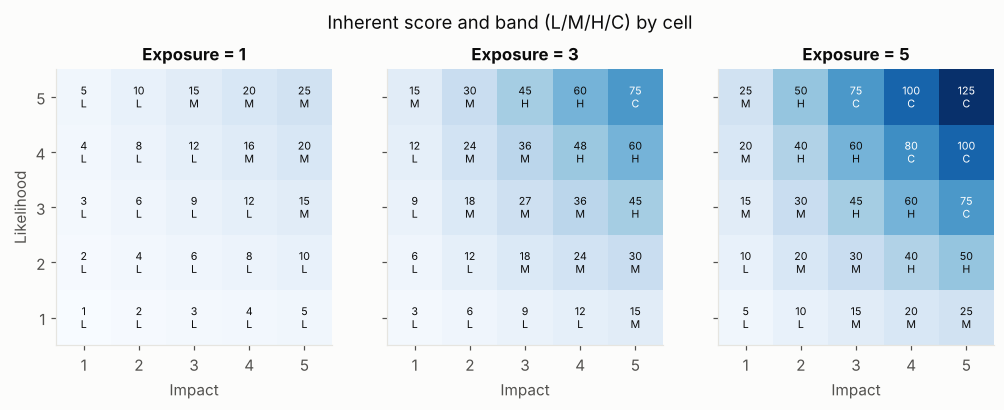

In [3]:
vals = r.distinct_lie_scores()
print(len(vals), 'distinct scores:', vals)
dist = r.band_distribution(); print({k: f'{v:.0%}' for k, v in dist.items()})
grid = np.array([[l*i for i in range(1,6)] for l in range(1,6)])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, e in zip(axes, (1, 3, 5)):
    im = ax.imshow(grid*e, origin='lower', cmap='Blues', vmin=1, vmax=125)
    for (a, b), v in np.ndenumerate(grid*e):
        ax.text(b, a, f'{v}\n{r.band(v)[0]}', ha='center', va='center', fontsize=7,
                color='white' if v > 70 else plotting.INK)
    ax.set_title(f'Exposure = {e}'); ax.set_xticks(range(5), range(1,6)); ax.set_yticks(range(5), range(1,6))
    ax.set_xlabel('Impact'); ax.grid(False)
axes[0].set_ylabel('Likelihood'); fig.suptitle('Inherent score and band (L/M/H/C) by cell', y=1.02); plt.show()

## 3 · Synthetic register and ranking stability under assessor noise
Noise model: each 1–5 rating moves ±1 with probability *p* (an assumption to be replaced by the E3 empirical noise estimate). We compare Kendall τ-b against the noise-free ranking and the share of the true top-3 retained.

In [4]:
rng = np.random.default_rng(42)
lie = rng.integers(1, 6, size=(20, 3))
rows = []
for agg in r.AGGREGATORS:
    for p in (0.1, 0.2, 0.3, 0.5):
        s = r.ranking_stability(lie, agg, p_shift=p, n_sim=400, seed=1)
        rows.append({'aggregator': agg, 'p_shift': p, **s})
stab = pd.DataFrame(rows)
stab.pivot(index='aggregator', columns='p_shift', values='tau_mean')

p_shift,0.1,0.2,0.3,0.5
aggregator,,,,
geomean,0.910,0.849,0.801,0.733
max,0.906,0.820,0.736,0.590
product,0.910,0.849,0.801,0.733
sum,0.943,0.896,0.855,0.784
weighted_sum,0.922,0.867,0.821,0.746


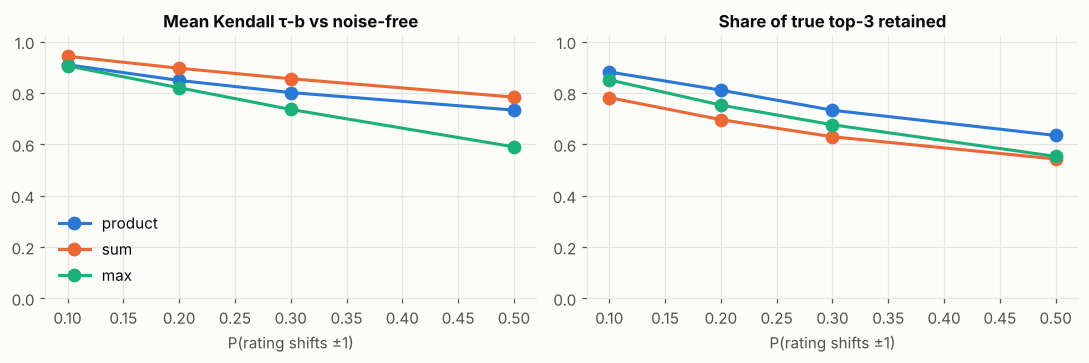

Tie share among 20 synthetic risks (product): 0.053 | max: 0.353


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, metric, title in [(axes[0], 'tau_mean', 'Mean Kendall τ-b vs noise-free'), (axes[1], 'topk_overlap', 'Share of true top-3 retained')]:
    for i, agg in enumerate(['product', 'sum', 'max']):   # 3 series max; others in table above
        d = stab[stab.aggregator == agg]
        ax.plot(d.p_shift, d[metric], marker='o', color=plotting.SERIES[i], label=agg)
    ax.set_title(title); ax.set_xlabel('P(rating shifts ±1)'); ax.set_ylim(0, 1.02)
axes[0].legend(); plt.tight_layout(); plt.show()
print('Tie share among 20 synthetic risks (product):', round(r.tie_share([a*b*c for a,b,c in lie]), 3),
      '| max:', round(r.tie_share([max(x) for x in lie]), 3))

**Reading:** with even modest noise the ordinal ranking degrades quickly — this motivates E3 (measure real inter-rater noise) and the rule that **release blockers must not depend on the score**.

## 4 · Sensitivity of the residual score to the effectiveness assumption

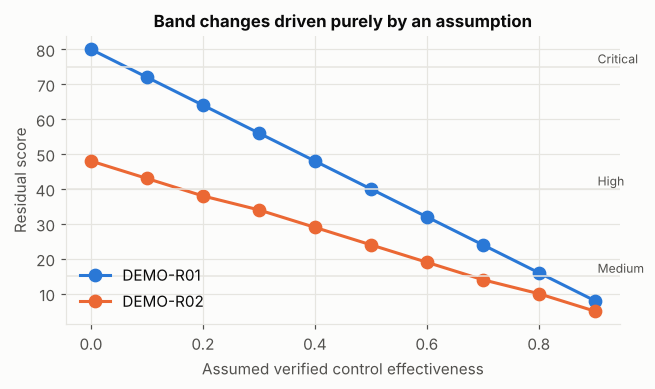

In [6]:
eff = np.linspace(0, 0.9, 10)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for i, d in enumerate(demo):
    ax.plot(eff, [r.residual_score(d.inherent, e) for e in eff], marker='o', color=plotting.SERIES[i], label=d.risk_id)
for thr, lbl in [(75,'Critical'),(40,'High'),(15,'Medium')]:
    ax.axhline(thr, color=plotting.GRID, lw=1); ax.text(0.905, thr+1, lbl, fontsize=8, color=plotting.INK2)
ax.set_xlabel('Assumed verified control effectiveness'); ax.set_ylabel('Residual score'); ax.legend(); ax.set_title('Band changes driven purely by an assumption'); plt.show()

## 5 · Uncertainty-aware Monte Carlo (FAIR-inspired)
Ranges replace point estimates: frequency as Beta-PERT(min, mode, max) events/year, loss per event as a lognormal fitted to an elicited 90 % CI, annual loss = Σ Poisson(freq) events. Values are synthetic.

In [7]:
sc = [r.UncertainScenario(f'S{i:02d}', *sorted(rng.uniform(0.01, 1.2, 3)),
        *(lambda lo: (lo, lo*rng.uniform(3, 30)))(rng.uniform(2e3, 6e4)), 0.2, 0.6) for i in range(20)]
res = [r.simulate_annual_loss(s, n=20000, seed=i) for i, s in enumerate(sc)]
mc = pd.DataFrame({'risk': [x.risk_id for x in res], 'mean_€': [x.mean for x in res],
                   'p90_€': [x.quantile(.9) for x in res], 'P(>100k)': [x.prob_exceed(1e5) for x in res]})
top = r.rank_probability(res, top_k=3); mc['P(top-3)'] = mc.risk.map(top)
from scipy.stats import kendalltau
print('Kendall τ mean-ALE vs P90:', round(kendalltau(mc['mean_€'], mc['p90_€']).statistic, 3))
mc.sort_values('mean_€', ascending=False).head(8)

Kendall τ mean-ALE vs P90: 0.968


,risk,mean_€,p90_€,P(>100k),P(top-3)
14,S14,357506.022,1.034e+06,0.494,0.446
6,S06,213539.020,6.478e+05,0.418,0.355
17,S17,170480.349,4.793e+05,0.436,0.353
2,S02,133996.403,3.851e+05,0.363,0.283
9,S09,114557.903,3.604e+05,0.264,0.207
0,S00,112447.850,3.250e+05,0.364,0.267
4,S04,95938.312,3.135e+05,0.217,0.172
3,S03,68933.627,2.167e+05,0.274,0.181


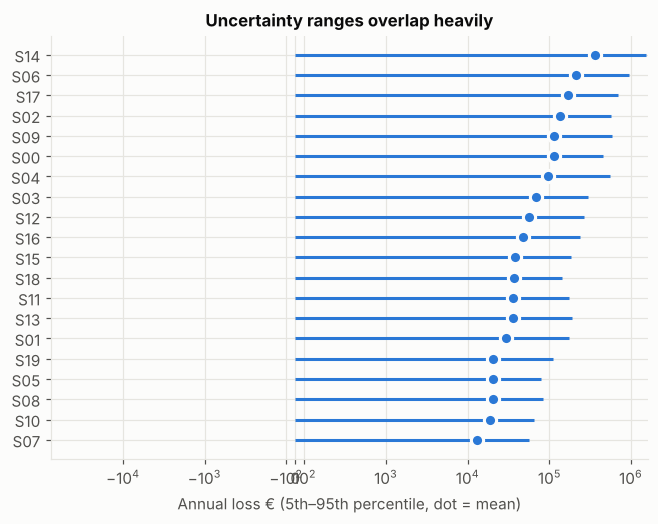

In [8]:
d = mc.sort_values('mean_€')
fig, ax = plt.subplots(figsize=(7, 5))
lo = [x.quantile(.05) for x in res]; hi = [x.quantile(.95) for x in res]
q = pd.DataFrame({'risk': mc.risk, 'lo': lo, 'hi': hi, 'mean': mc['mean_€']}).set_index('risk').loc[d.risk]
ax.hlines(range(len(q)), q.lo, q.hi, color=plotting.SERIES[0], lw=2)
ax.plot(q['mean'], range(len(q)), 'o', color=plotting.SERIES[0], markeredgecolor=plotting.SURFACE, markeredgewidth=2)
ax.set_yticks(range(len(q)), q.index); ax.set_xscale('symlog', linthresh=1e3)
ax.set_xlabel('Annual loss € (5th–95th percentile, dot = mean)'); ax.set_title('Uncertainty ranges overlap heavily'); plt.show()

## 6 · Take-aways to carry into the manuscript
* `L×I×E` is a usable *triage* aid but has coarse resolution (30 values) and is sensitive to ±1 rating noise.
* Residual bands can be moved across thresholds by the effectiveness assumption alone → record the evidence ID for every effectiveness value (new workbook column AH).
* Monte Carlo output exposes overlap between risks that point scores hide; report `P(top-k)` rather than a single rank.
* **Hypothesis for E3:** explicit, evidence-linked assumptions increase inter-rater agreement more than the choice of numeric model.